# Customer Segmentation using K-Means Clustering on Tips Dataset
In this notebook, we perform unsupervised learning with **K-Means Clustering** on the restaurant `tips_data.csv` dataset, segmenting customers based on **Total Bill** and **Tip** amounts.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import os


## 1. Load Data & Exploratory Analysis


In [2]:
file_path = "tips_data.csv" if os.path.exists("tips_data.csv") else "November/5Nov/tips_data.csv"
df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

print("\nMissing Values Count:")
print(df.isnull().sum())


Dataset Shape: (244, 7)

First 5 rows:
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1         NaN  1.66    Male     No  Sun     NaN     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31     NaN     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4

Missing Values Count:
total_bill    1
tip           0
sex           1
smoker        0
day           0
time          1
size          0
dtype: int64


### Handle Missing Values
K-Means and StandardScaler do not accept `NaN` values, so we drop any rows missing `total_bill` or `tip`.


In [3]:
# Drop rows missing total_bill or tip
df = df.dropna(subset=['total_bill', 'tip']).reset_index(drop=True)
print("Cleaned Dataset Shape:", df.shape)

print("\nSummary Statistics:")
print(df[['total_bill', 'tip']].describe().round(2))


Cleaned Dataset Shape: (243, 7)

Summary Statistics:
       total_bill     tip
count      243.00  243.00
mean        19.82    3.00
std          8.90    1.38
min          3.07    1.00
25%         13.38    2.00
50%         17.81    2.92
75%         24.17    3.58
max         50.81   10.00


## 2. Visualize Raw Data (Total Bill vs Tip)


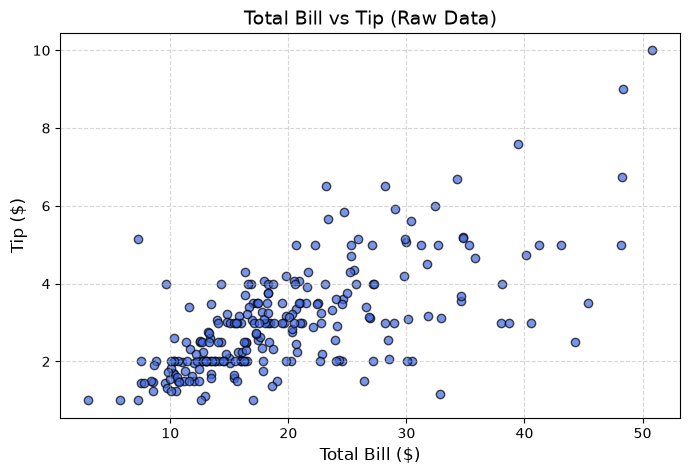

In [4]:
plt.figure(figsize=(8, 5))
plt.scatter(df['total_bill'], df['tip'], color='royalblue', edgecolor='black', alpha=0.7)
plt.title("Total Bill vs Tip (Raw Data)", fontsize=14)
plt.xlabel("Total Bill ($)", fontsize=12)
plt.ylabel("Tip ($)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


## 3. Feature Selection & Feature Scaling (StandardScaler)
*Total Bill ranges up to ~$50 while Tip ranges up to ~$10. Feature scaling is essential so Euclidean distance isn't dominated by the bill.*


In [5]:
features = ['total_bill', 'tip']
X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Sample Scaled Features (first 5 rows):")
print(np.round(X_scaled[:5], 3))


Sample Scaled Features (first 5 rows):
[[-0.319 -1.444]
 [ 0.133  0.359]
 [ 0.434  0.222]
 [ 0.537  0.439]
 [ 0.615  1.236]]


## 4. The Elbow Method (Finding Optimal K)
We compute WCSS (Inertia) for $K = 1$ to $10$ to find the optimal number of clusters.


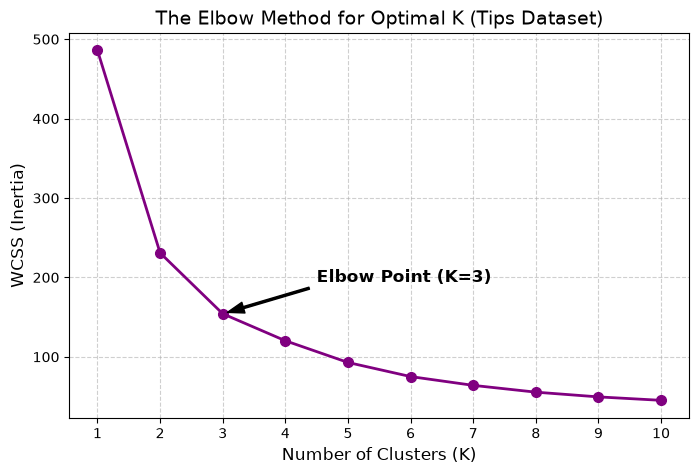

In [6]:
wcss = []
k_range = range(1, 11)

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_range, wcss, marker='o', color='purple', linewidth=2, markersize=7)
plt.title("The Elbow Method for Optimal K (Tips Dataset)", fontsize=14)
plt.xlabel("Number of Clusters (K)", fontsize=12)
plt.ylabel("WCSS (Inertia)", fontsize=12)
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.6)

# Annotate Elbow at K=3
plt.annotate('Elbow Point (K=3)', xy=(3, wcss[2]), xytext=(4.5, wcss[2] + 40),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
             fontsize=12, fontweight='bold')
plt.show()


## 5. Train K-Means Model (K=3) & Silhouette Evaluation


In [7]:
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# Calculate Silhouette Score
sil_score = silhouette_score(X_scaled, df['Cluster'])
print(f"Optimal K: {optimal_k}")
print(f"WCSS / Inertia: {kmeans.inertia_:.2f}")
print(f"Silhouette Score: {sil_score:.4f}")

# Inverse transform centroids to original dollar scale
centroids = scaler.inverse_transform(kmeans.cluster_centers_)
print("\nCluster Centroids (Original Dollar Units):")
for i, c in enumerate(centroids):
    print(f"Cluster {i}: Total Bill = ${c[0]:.2f}, Tip = ${c[1]:.2f}")


Optimal K: 3
WCSS / Inertia: 154.24
Silhouette Score: 0.4243

Cluster Centroids (Original Dollar Units):
Cluster 0: Total Bill = $12.80, Tip = $1.89
Cluster 1: Total Bill = $20.73, Tip = $3.23
Cluster 2: Total Bill = $34.97, Tip = $5.18


## 6. Visualize Clusters and Centroids


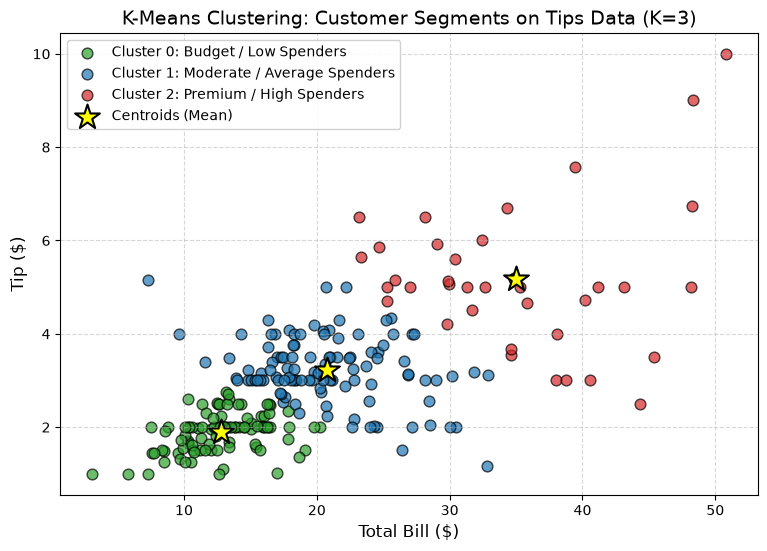

In [8]:
plt.figure(figsize=(9, 6))

colors = ['#2ca02c', '#1f77b4', '#d62728']
labels = ['Cluster 0: Budget / Low Spenders', 
          'Cluster 1: Moderate / Average Spenders', 
          'Cluster 2: Premium / High Spenders']

for i in range(optimal_k):
    cluster_points = df[df['Cluster'] == i]
    plt.scatter(cluster_points['total_bill'], cluster_points['tip'],
                color=colors[i], label=labels[i], alpha=0.7, edgecolors='k', s=60)

# Plot Centroids
plt.scatter(centroids[:, 0], centroids[:, 1],
            color='yellow', marker='*', s=350, edgecolor='black', linewidth=1.5, label='Centroids (Mean)')

plt.title("K-Means Clustering: Customer Segments on Tips Data (K=3)", fontsize=14)
plt.xlabel("Total Bill ($)", fontsize=12)
plt.ylabel("Tip ($)", fontsize=12)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


## 7. Cluster Profiles & Business Interpretation


In [9]:
cluster_summary = df.groupby('Cluster').agg({
    'total_bill': ['count', 'min', 'mean', 'max'],
    'tip': ['min', 'mean', 'max']
}).round(2)

cluster_summary.columns = ['Count', 'Min Bill', 'Avg Bill', 'Max Bill', 'Min Tip', 'Avg Tip', 'Max Tip']
print("Cluster Profiles Summary:")
print(cluster_summary)


Cluster Profiles Summary:
         Count  Min Bill  Avg Bill  Max Bill  Min Tip  Avg Tip  Max Tip
Cluster                                                                
0           96      3.07     12.80     20.23     1.00     1.89     2.75
1          109      7.25     20.73     32.90     1.17     3.23     5.15
2           38     23.17     34.97     50.81     2.50     5.18    10.00


## 8. Predict Cluster for New Diners


In [10]:
new_diners = pd.DataFrame({
    'total_bill': [11.50, 22.00, 42.50],
    'tip': [1.50, 3.50, 6.00]
})

# Scale using the fitted scaler
new_diners_scaled = scaler.transform(new_diners)
new_diners['Predicted_Cluster'] = kmeans.predict(new_diners_scaled)

segment_names = {
    0: 'Budget / Low Spenders',
    1: 'Moderate / Average Spenders',
    2: 'Premium / High Spenders'
}
new_diners['Segment'] = new_diners['Predicted_Cluster'].map(segment_names)

print("Predictions for New Customers:")
print(new_diners)


Predictions for New Customers:
   total_bill  tip  Predicted_Cluster                      Segment
0        11.5  1.5                  0        Budget / Low Spenders
1        22.0  3.5                  1  Moderate / Average Spenders
2        42.5  6.0                  2      Premium / High Spenders
